In [17]:
# Assignment 2 - Part A Object Recognition Implementation
# Dataset: CUB-200-2011
# Task: Compare classical and deep learning methods for bird species recognition
# Classical Approach:
# Experiment 1 = Whole image + HOG feature extraction + Linear SVM classifier
# Experiment 3 = Bounding box crop + HOG feature extraction + Linear SVM classifier
# Cell 1: Imports and setup
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

# Dataset path
DATASET_DIR = os.path.join("data", "CUB_200_2011")  # see README for download
IMAGE_DIR = os.path.join(DATASET_DIR, "images")

# Output folder for saved results
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Dataset folder:", os.path.abspath(DATASET_DIR))
print("Images folder exists:", os.path.exists(IMAGE_DIR))
print("Output folder:", os.path.abspath(OUTPUT_DIR))


Dataset folder: data/CUB_200_2011
Images folder exists: True
Output folder: outputs


In [18]:
# Load CUB-200-2011 metadata files

images_df = pd.read_csv(
    os.path.join(DATASET_DIR, "images.txt"),
    sep=" ",
    names=["image_id", "image_path"]
)

labels_df = pd.read_csv(
    os.path.join(DATASET_DIR, "image_class_labels.txt"),
    sep=" ",
    names=["image_id", "class_id"]
)

classes_df = pd.read_csv(
    os.path.join(DATASET_DIR, "classes.txt"),
    sep=" ",
    names=["class_id", "class_name"]
)

bboxes_df = pd.read_csv(
    os.path.join(DATASET_DIR, "bounding_boxes.txt"),
    sep=" ",
    names=["image_id", "x", "y", "width", "height"]
)

split_df = pd.read_csv(
    os.path.join(DATASET_DIR, "train_test_split.txt"),
    sep=" ",
    names=["image_id", "is_train"]
)

# Merge all metadata into one table
metadata = images_df.merge(labels_df, on="image_id")
metadata = metadata.merge(classes_df, on="class_id")
metadata = metadata.merge(bboxes_df, on="image_id")
metadata = metadata.merge(split_df, on="image_id")

# Full image path
metadata["full_path"] = metadata["image_path"].apply(lambda p: os.path.join(IMAGE_DIR, p))

print(metadata.head())
print("Total images:", len(metadata))
print("Number of classes:", metadata["class_id"].nunique())
print("Training images:", metadata["is_train"].sum())
print("Testing images:", (metadata["is_train"] == 0).sum())

   image_id                                         image_path  class_id  \
0         1  001.Black_footed_Albatross/Black_Footed_Albatr...         1   
1         2  001.Black_footed_Albatross/Black_Footed_Albatr...         1   
2         3  001.Black_footed_Albatross/Black_Footed_Albatr...         1   
3         4  001.Black_footed_Albatross/Black_Footed_Albatr...         1   
4         5  001.Black_footed_Albatross/Black_Footed_Albatr...         1   

                   class_name      x      y  width  height  is_train  \
0  001.Black_footed_Albatross   60.0   27.0  325.0   304.0         0   
1  001.Black_footed_Albatross  139.0   30.0  153.0   264.0         1   
2  001.Black_footed_Albatross   14.0  112.0  388.0   186.0         0   
3  001.Black_footed_Albatross  112.0   90.0  255.0   242.0         1   
4  001.Black_footed_Albatross   70.0   50.0  134.0   303.0         1   

                                           full_path  
0  .\images\001.Black_footed_Albatross/Black_Foot...  


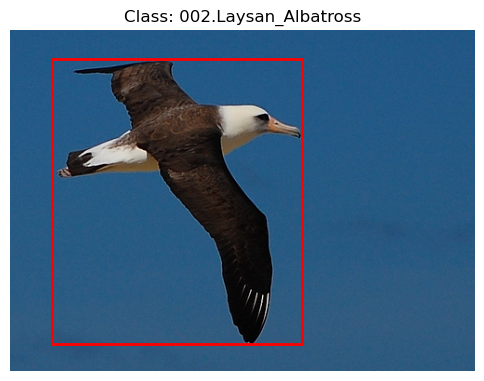

Image ID: 74
Class ID: 2
Class name: 002.Laysan_Albatross
Image path: .\images\002.Laysan_Albatross/Laysan_Albatross_0085_564.jpg
Bounding box: x = 45.0 y = 31.0 width = 268.0 height = 306.0


In [19]:
# Cell 3: Visual check of image and bounding box

import matplotlib.patches as patches

# Select one sample image
sample = metadata.iloc[73]

# Open image
img = Image.open(sample["full_path"]).convert("RGB")

# Create figure
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img)

# Draw bounding box
rect = patches.Rectangle(
    (sample["x"], sample["y"]),      # top-left corner: x, y
    sample["width"],                 # box width
    sample["height"],                # box height
    linewidth=2,
    edgecolor="red",
    facecolor="none"
)

ax.add_patch(rect)

# Display title and remove axis
ax.set_title(f"Class: {sample['class_name']}")
ax.axis("off")

plt.show()

# Print sample information
print("Image ID:", sample["image_id"])
print("Class ID:", sample["class_id"])
print("Class name:", sample["class_name"])
print("Image path:", sample["full_path"])
print("Bounding box: x =", sample["x"], 
      "y =", sample["y"], 
      "width =", sample["width"], 
      "height =", sample["height"])

In [20]:
# Cell 4: Create train and test metadata splits

train_metadata = metadata[metadata["is_train"] == 1].reset_index(drop=True)
test_metadata = metadata[metadata["is_train"] == 0].reset_index(drop=True)

print("Training set shape:", train_metadata.shape)
print("Testing set shape:", test_metadata.shape)

print("\nNumber of classes in training set:", train_metadata["class_id"].nunique())
print("Number of classes in testing set:", test_metadata["class_id"].nunique())

print("\nTraining images:", len(train_metadata))
print("Testing images:", len(test_metadata))

# Check class distribution
class_distribution = metadata.groupby("class_name")["image_id"].count().reset_index()
class_distribution.columns = ["class_name", "num_images"]

print("\nFirst 10 class distributions:")
print(class_distribution.head(10))

Training set shape: (5994, 10)
Testing set shape: (5794, 10)

Number of classes in training set: 200
Number of classes in testing set: 200

Training images: 5994
Testing images: 5794

First 10 class distributions:
                   class_name  num_images
0  001.Black_footed_Albatross          60
1        002.Laysan_Albatross          60
2         003.Sooty_Albatross          58
3       004.Groove_billed_Ani          60
4          005.Crested_Auklet          44
5            006.Least_Auklet          41
6         007.Parakeet_Auklet          53
7       008.Rhinoceros_Auklet          48
8        009.Brewer_Blackbird          59
9    010.Red_winged_Blackbird          60


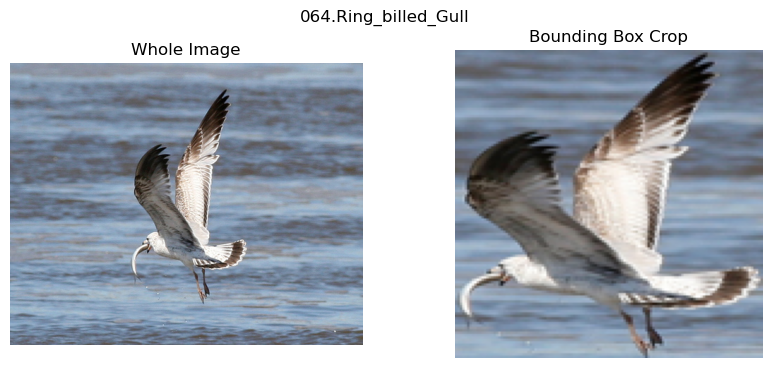

In [21]:
# Cell 5: Image preprocessing functions

import cv2
from tqdm import tqdm

# Image size used for the classical HOG + SVM experiments
CLASSICAL_IMG_SIZE = (128, 128)

# Image size used later for deep learning models
DEEP_IMG_SIZE = (224, 224)


def load_whole_image(image_path, image_size=CLASSICAL_IMG_SIZE):
    """
    Loads the entire image and resizes it to a fixed size.
    This is used for the whole-image experiments.
    """
    img = Image.open(image_path).convert("RGB")
    img = img.resize(image_size)
    return np.array(img)


def load_bbox_crop(row, image_size=CLASSICAL_IMG_SIZE):
    """
    Loads an image, crops the bird region using the bounding box,
    and resizes the crop to a fixed size.
    
    Bounding box format:
    x, y, width, height
    """
    img = Image.open(row["full_path"]).convert("RGB")
    
    x = int(row["x"])
    y = int(row["y"])
    w = int(row["width"])
    h = int(row["height"])
    
    # Crop using bounding box
    crop = img.crop((x, y, x + w, y + h))
    
    # Resize crop
    crop = crop.resize(image_size)
    
    return np.array(crop)


def show_whole_and_crop(row):
    """
    Displays the original whole image and the bounding box crop side by side.
    This is just for checking that preprocessing works correctly.
    """
    whole_img = Image.open(row["full_path"]).convert("RGB")
    crop_img = load_bbox_crop(row, image_size=CLASSICAL_IMG_SIZE)
    
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    
    axes[0].imshow(whole_img)
    axes[0].set_title("Whole Image")
    axes[0].axis("off")
    
    axes[1].imshow(crop_img)
    axes[1].set_title("Bounding Box Crop")
    axes[1].axis("off")
    
    plt.suptitle(row["class_name"])
    plt.show()


# Test the preprocessing on one sample
random_sample = metadata.sample(1, random_state=69).iloc[0]
show_whole_and_crop(random_sample)


Test image shape: (128, 128, 3)
HOG feature vector length: 8100
First 10 HOG values:
[0.06281072 0.00772487 0.01967784 0.04089419 0.34819694 0.17278263
 0.07657524 0.05577383 0.         0.10534926]


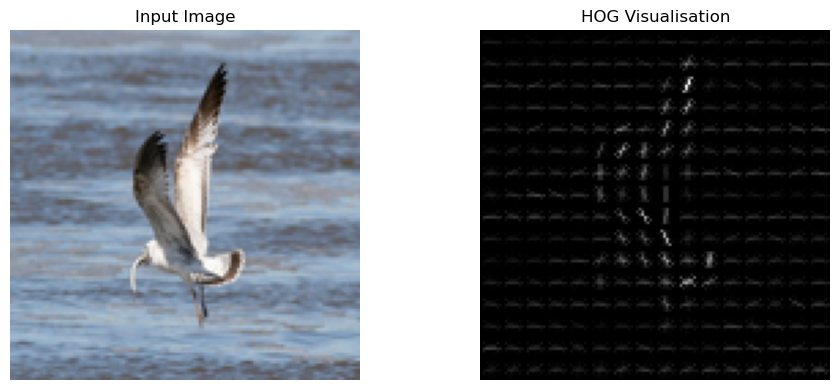

In [22]:
# Cell 6: HOG feature extraction function

from skimage.feature import hog

def extract_hog_features(img, visualise=False):
    """
    Extract Histogram of Oriented Gradients (HOG) features from an RGB image.

    HOG is a handcrafted feature descriptor. It captures edge direction and
    local shape information by measuring intensity gradients in small cells.
    This fits the classical approach requirement because the features are
    manually designed rather than learned by a neural network.

    Parameters:
    - img: RGB image as a NumPy array
    - visualise: if True, also return a HOG visualisation image

    Returns:
    - features: HOG feature vector
    - hog_image: optional HOG visualisation
    """

    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

    if visualise:
        features, hog_image = hog(
            gray,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm="L2-Hys",
            transform_sqrt=True,
            feature_vector=True,
            visualize=True
        )
        return features, hog_image

    features = hog(
        gray,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        transform_sqrt=True,
        feature_vector=True
    )

    return features


# Test HOG on the same random sample
test_img = load_whole_image(random_sample["full_path"], image_size=CLASSICAL_IMG_SIZE)
test_features, hog_vis = extract_hog_features(test_img, visualise=True)

print("Test image shape:", test_img.shape)
print("HOG feature vector length:", len(test_features))
print("First 10 HOG values:")
print(test_features[:10])

# Display original image and HOG visualisation
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(test_img)
axes[0].set_title("Input Image")
axes[0].axis("off")

axes[1].imshow(hog_vis, cmap="gray")
axes[1].set_title("HOG Visualisation")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [23]:
# Cell 7: Build HOG feature datasets for classical experiments

from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import time


# ---------------------------------------------------------
# TEMPORARY SPEED SETTING
# ---------------------------------------------------------
# Use a small subset first to check that the pipeline works.
# USE_SMALL_SUBSET to False for the full experiment.
USE_SMALL_SUBSET = False  #True
MAX_CLASSES = 20   # use first 20 bird species for testing/debugging

if USE_SMALL_SUBSET:
    train_data = train_metadata[train_metadata["class_id"] <= MAX_CLASSES].reset_index(drop=True)
    test_data = test_metadata[test_metadata["class_id"] <= MAX_CLASSES].reset_index(drop=True)
else:
    train_data = train_metadata.copy()
    test_data = test_metadata.copy()

print("Training images used:", len(train_data))
print("Testing images used:", len(test_data))
print("Number of classes used:", train_data["class_id"].nunique())


def build_hog_dataset(dataframe, input_type="whole"):
    """
    Builds HOG feature matrix X and label vector y.
    
    input_type:
    - 'whole': use the full image
    - 'bbox': use the bounding box crop only
    """
    X = []
    y = []
    
    start_time = time.time()
    
    for _, row in tqdm(dataframe.iterrows(), total=len(dataframe)):
        
        if input_type == "whole":
            img = load_whole_image(row["full_path"], image_size=CLASSICAL_IMG_SIZE)
        elif input_type == "bbox":
            img = load_bbox_crop(row, image_size=CLASSICAL_IMG_SIZE)
        else:
            raise ValueError("input_type must be either 'whole' or 'bbox'")
        
        features = extract_hog_features(img)
        X.append(features)
        y.append(row["class_id"])
    
    X = np.array(X)
    y = np.array(y)
    
    elapsed = time.time() - start_time
    print(f"Finished building {input_type} HOG dataset in {elapsed:.2f} seconds")
    print("X shape:", X.shape)
    print("y shape:", y.shape)
    
    return X, y


# Build HOG datasets for whole-image experiment
X_train_whole_hog, y_train = build_hog_dataset(train_data, input_type="whole")
X_test_whole_hog, y_test = build_hog_dataset(test_data, input_type="whole")

# Build HOG datasets for bounding-box experiment
X_train_bbox_hog, y_train_bbox = build_hog_dataset(train_data, input_type="bbox")
X_test_bbox_hog, y_test_bbox = build_hog_dataset(test_data, input_type="bbox")

Training images used: 5994
Testing images used: 5794
Number of classes used: 200


100%|██████████| 5994/5994 [02:40<00:00, 37.30it/s]


Finished building whole HOG dataset in 161.15 seconds
X shape: (5994, 8100)
y shape: (5994,)


100%|██████████| 5794/5794 [02:36<00:00, 37.13it/s]


Finished building whole HOG dataset in 156.45 seconds
X shape: (5794, 8100)
y shape: (5794,)


100%|██████████| 5994/5994 [02:34<00:00, 38.78it/s]


Finished building bbox HOG dataset in 154.93 seconds
X shape: (5994, 8100)
y shape: (5994,)


100%|██████████| 5794/5794 [02:28<00:00, 38.91it/s]


Finished building bbox HOG dataset in 149.20 seconds
X shape: (5794, 8100)
y shape: (5794,)


In [24]:
# Cell 8: Train and evaluate faster HOG + Linear SVM models
# Experiments covered:
# Experiment 1 = HOG + Linear SVM using whole images
# Experiment 3 = HOG + Linear SVM using bounding box crops

from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score
import pandas as pd
import time
import os
import joblib


def train_evaluate_fast_linear_svm(X_train, y_train, X_test, y_test, experiment_name):
    """
    Trains and evaluates a classical machine learning model.

    Method:
    - Handcrafted feature: HOG
    - Classifier: Linear SVM trained using stochastic gradient descent

    This satisfies the classical approach requirement because the image features
    are manually extracted using HOG, and the classifier is a traditional
    machine learning classifier rather than a deep learning model.

    SGDClassifier with loss='hinge' optimises a linear SVM objective.
    It is much faster than LinearSVC for high-dimensional HOG features.
    """

    print("=" * 80)
    print(experiment_name)
    print("=" * 80)

    # Build the model pipeline
    # StandardScaler is used because SVM-style models perform better when
    # feature values are normalised.
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("linear_svm", SGDClassifier(
            loss="hinge",          # hinge loss = linear SVM objective
            penalty="l2",          # L2 regularisation
            alpha=0.0001,          # regularisation strength
            max_iter=1000,         # maximum training iterations
            tol=1e-3,              # stopping tolerance
            random_state=42,
            n_jobs=-1              # use all available CPU cores
        ))
    ])

    # Train model
    start_time = time.time()
    model.fit(X_train, y_train)
    training_time = time.time() - start_time

    # Predict on test set
    y_pred = model.predict(X_test)

    # Overall accuracy
    accuracy = accuracy_score(y_test, y_pred)

    print(f"Training time: {training_time:.2f} seconds")
    print(f"Overall accuracy: {accuracy:.4f}")
    print(f"Overall accuracy percentage: {accuracy * 100:.2f}%")

    return model, y_pred, accuracy, training_time


# ---------------------------------------------------------
# Experiment 1: Classical HOG + Linear SVM using whole images
# ---------------------------------------------------------

svm_whole_model, y_pred_whole, acc_whole, time_whole = train_evaluate_fast_linear_svm(
    X_train_whole_hog,
    y_train,
    X_test_whole_hog,
    y_test,
    "Experiment 1: Classical HOG + Linear SVM using Whole Images"
)


# ---------------------------------------------------------
# Experiment 3: Classical HOG + Linear SVM using bounding box crops
# ---------------------------------------------------------

svm_bbox_model, y_pred_bbox, acc_bbox, time_bbox = train_evaluate_fast_linear_svm(
    X_train_bbox_hog,
    y_train_bbox,
    X_test_bbox_hog,
    y_test_bbox,
    "Experiment 3: Classical HOG + Linear SVM using Bounding Box Crops"
)


# ---------------------------------------------------------
# Create overall results table
# ---------------------------------------------------------

classical_results = pd.DataFrame({
    "Experiment": [
        "Experiment 1",
        "Experiment 3"
    ],
    "Method": [
        "HOG + Linear SVM",
        "HOG + Linear SVM"
    ],
    "Input Type": [
        "Whole Image",
        "Bounding Box Crop"
    ],
    "Feature Type": [
        "HOG",
        "HOG"
    ],
    "Classifier": [
        "Linear SVM using SGD",
        "Linear SVM using SGD"
    ],
    "Training Time (s)": [
        time_whole,
        time_bbox
    ],
    "Accuracy": [
        acc_whole,
        acc_bbox
    ],
    "Accuracy (%)": [
        acc_whole * 100,
        acc_bbox * 100
    ]
})

print("\nClassical Results Summary:")
display(classical_results)


# ---------------------------------------------------------
# Save models and overall results
# ---------------------------------------------------------

os.makedirs(OUTPUT_DIR, exist_ok=True)

joblib.dump(
    svm_whole_model,
    os.path.join(OUTPUT_DIR, "exp1_hog_linear_svm_whole_model.joblib")
)

joblib.dump(
    svm_bbox_model,
    os.path.join(OUTPUT_DIR, "exp3_hog_linear_svm_bbox_model.joblib")
)

classical_results.to_csv(
    os.path.join(OUTPUT_DIR, "classical_hog_svm_overall_results.csv"),
    index=False
)

print("\nSaved:")
print("- Experiment 1 model: exp1_hog_linear_svm_whole_model.joblib")
print("- Experiment 3 model: exp3_hog_linear_svm_bbox_model.joblib")
print("- Overall results: classical_hog_svm_overall_results.csv")

Experiment 1: Classical HOG + Linear SVM using Whole Images
Training time: 196.82 seconds
Overall accuracy: 0.0271
Overall accuracy percentage: 2.71%
Experiment 3: Classical HOG + Linear SVM using Bounding Box Crops
Training time: 175.17 seconds
Overall accuracy: 0.0822
Overall accuracy percentage: 8.22%

Classical Results Summary:


,Experiment,Method,Input Type,Feature Type,Classifier,Training Time (s),Accuracy,Accuracy (%)
0,Experiment 1,HOG + Linear SVM,Whole Image,HOG,Linear SVM using SGD,196.823059,0.027097,2.709700
1,Experiment 3,HOG + Linear SVM,Bounding Box Crop,HOG,Linear SVM using SGD,175.171091,0.082154,8.215395



Saved:
- Experiment 1 model: exp1_hog_linear_svm_whole_model.joblib
- Experiment 3 model: exp3_hog_linear_svm_bbox_model.joblib
- Overall results: classical_hog_svm_overall_results.csv


In [25]:
# Cell 9: Class-wise accuracy for classical experiments

def compute_classwise_accuracy(y_true, y_pred, metadata_subset, experiment_name):
    """
    Computes accuracy for each bird class.
    Returns a table with class_id, class_name, number of test images, correct predictions, and accuracy.
    """
    results = []

    # Get class name mapping from metadata
    class_map = metadata_subset[["class_id", "class_name"]].drop_duplicates()

    for class_id in sorted(np.unique(y_true)):
        class_indices = np.where(y_true == class_id)[0]

        total_images = len(class_indices)
        correct_predictions = np.sum(y_pred[class_indices] == y_true[class_indices])
        class_accuracy = correct_predictions / total_images if total_images > 0 else 0

        class_name = class_map[class_map["class_id"] == class_id]["class_name"].iloc[0]

        results.append({
            "experiment": experiment_name,
            "class_id": class_id,
            "class_name": class_name,
            "test_images": total_images,
            "correct_predictions": correct_predictions,
            "class_accuracy": class_accuracy,
            "class_accuracy_percent": class_accuracy * 100
        })

    return pd.DataFrame(results)


# Class-wise accuracy for Experiment 1
classwise_whole = compute_classwise_accuracy(
    y_test,
    y_pred_whole,
    test_data,
    "Experiment 1: Whole Image HOG + SVM"
)

# Class-wise accuracy for Experiment 3
classwise_bbox = compute_classwise_accuracy(
    y_test_bbox,
    y_pred_bbox,
    test_data,
    "Experiment 3: Bounding Box HOG + SVM"
)

print("Experiment 1 class-wise accuracy:")
display(classwise_whole.head(10))

print("Experiment 3 class-wise accuracy:")
display(classwise_bbox.head(10))

# Save class-wise results to CSV files for the report
classwise_whole.to_csv(os.path.join(OUTPUT_DIR, "classwise_accuracy_exp1_hog_svm_whole.csv"), index=False)
classwise_bbox.to_csv(os.path.join(OUTPUT_DIR, "classwise_accuracy_exp3_hog_svm_bbox.csv"), index=False)
print("Saved class-wise accuracy files to outputs folder.")

# Show easiest and hardest classes for report discussion

print("\nTop 10 classes for Experiment 1:")
display(classwise_whole.sort_values("class_accuracy_percent", ascending=False).head(10))

print("\nBottom 10 classes for Experiment 1:")
display(classwise_whole.sort_values("class_accuracy_percent", ascending=True).head(10))

print("\nTop 10 classes for Experiment 3:")
display(classwise_bbox.sort_values("class_accuracy_percent", ascending=False).head(10))

print("\nBottom 10 classes for Experiment 3:")
display(classwise_bbox.sort_values("class_accuracy_percent", ascending=True).head(10))

# Save top/bottom class summaries
top_bottom_exp1 = pd.concat([
    classwise_whole.sort_values("class_accuracy_percent", ascending=False).head(10).assign(group="Top 10"),
    classwise_whole.sort_values("class_accuracy_percent", ascending=True).head(10).assign(group="Bottom 10")
])

top_bottom_exp3 = pd.concat([
    classwise_bbox.sort_values("class_accuracy_percent", ascending=False).head(10).assign(group="Top 10"),
    classwise_bbox.sort_values("class_accuracy_percent", ascending=True).head(10).assign(group="Bottom 10")
])

top_bottom_exp1.to_csv(
    os.path.join(OUTPUT_DIR, "top_bottom_classes_exp1_hog_svm_whole.csv"),
    index=False
)

top_bottom_exp3.to_csv(
    os.path.join(OUTPUT_DIR, "top_bottom_classes_exp3_hog_svm_bbox.csv"),
    index=False
)

print("Saved top/bottom class accuracy summaries.")

Experiment 1 class-wise accuracy:


,experiment,class_id,class_name,test_images,correct_predictions,class_accuracy,class_accuracy_percent
0,Experiment 1: Whole Image HOG + SVM,1,001.Black_footed_Albatross,30,2,0.066667,6.666667
1,Experiment 1: Whole Image HOG + SVM,2,002.Laysan_Albatross,30,0,0.000000,0.000000
2,Experiment 1: Whole Image HOG + SVM,3,003.Sooty_Albatross,28,0,0.000000,0.000000
3,Experiment 1: Whole Image HOG + SVM,4,004.Groove_billed_Ani,30,0,0.000000,0.000000
4,Experiment 1: Whole Image HOG + SVM,5,005.Crested_Auklet,14,0,0.000000,0.000000
5,Experiment 1: Whole Image HOG + SVM,6,006.Least_Auklet,11,3,0.272727,27.272727
6,Experiment 1: Whole Image HOG + SVM,7,007.Parakeet_Auklet,23,2,0.086957,8.695652
7,Experiment 1: Whole Image HOG + SVM,8,008.Rhinoceros_Auklet,18,1,0.055556,5.555556
8,Experiment 1: Whole Image HOG + SVM,9,009.Brewer_Blackbird,29,0,0.000000,0.000000
9,Experiment 1: Whole Image HOG + SVM,10,010.Red_winged_Blackbird,30,3,0.100000,10.000000


Experiment 3 class-wise accuracy:


,experiment,class_id,class_name,test_images,correct_predictions,class_accuracy,class_accuracy_percent
0,Experiment 3: Bounding Box HOG + SVM,1,001.Black_footed_Albatross,30,3,0.100000,10.000000
1,Experiment 3: Bounding Box HOG + SVM,2,002.Laysan_Albatross,30,3,0.100000,10.000000
2,Experiment 3: Bounding Box HOG + SVM,3,003.Sooty_Albatross,28,2,0.071429,7.142857
3,Experiment 3: Bounding Box HOG + SVM,4,004.Groove_billed_Ani,30,1,0.033333,3.333333
4,Experiment 3: Bounding Box HOG + SVM,5,005.Crested_Auklet,14,1,0.071429,7.142857
5,Experiment 3: Bounding Box HOG + SVM,6,006.Least_Auklet,11,3,0.272727,27.272727
6,Experiment 3: Bounding Box HOG + SVM,7,007.Parakeet_Auklet,23,7,0.304348,30.434783
7,Experiment 3: Bounding Box HOG + SVM,8,008.Rhinoceros_Auklet,18,1,0.055556,5.555556
8,Experiment 3: Bounding Box HOG + SVM,9,009.Brewer_Blackbird,29,0,0.000000,0.000000
9,Experiment 3: Bounding Box HOG + SVM,10,010.Red_winged_Blackbird,30,0,0.000000,0.000000


Saved class-wise accuracy files to outputs folder.

Top 10 classes for Experiment 1:


,experiment,class_id,class_name,test_images,correct_predictions,class_accuracy,class_accuracy_percent
5,Experiment 1: Whole Image HOG + SVM,6,006.Least_Auklet,11,3,0.272727,27.272727
27,Experiment 1: Whole Image HOG + SVM,28,028.Brown_Creeper,29,6,0.206897,20.689655
144,Experiment 1: Whole Image HOG + SVM,145,145.Elegant_Tern,30,6,0.200000,20.000000
109,Experiment 1: Whole Image HOG + SVM,110,110.Geococcyx,30,6,0.200000,20.000000
112,Experiment 1: Whole Image HOG + SVM,113,113.Baird_Sparrow,20,3,0.150000,15.000000
183,Experiment 1: Whole Image HOG + SVM,184,184.Louisiana_Waterthrush,30,4,0.133333,13.333333
36,Experiment 1: Whole Image HOG + SVM,37,037.Acadian_Flycatcher,29,3,0.103448,10.344828
45,Experiment 1: Whole Image HOG + SVM,46,046.Gadwall,30,3,0.100000,10.000000
85,Experiment 1: Whole Image HOG + SVM,86,086.Pacific_Loon,30,3,0.100000,10.000000
87,Experiment 1: Whole Image HOG + SVM,88,088.Western_Meadowlark,30,3,0.100000,10.000000


... (3 outputs left out)

,experiment,class_id,class_name,test_images,correct_predictions,class_accuracy,class_accuracy_percent
186,Experiment 3: Bounding Box HOG + SVM,187,187.American_Three_toed_Woodpecker,20,9,0.450000,45.000000
104,Experiment 3: Bounding Box HOG + SVM,105,105.Whip_poor_Will,19,8,0.421053,42.105263
82,Experiment 3: Bounding Box HOG + SVM,83,083.White_breasted_Kingfisher,30,12,0.400000,40.000000
100,Experiment 3: Bounding Box HOG + SVM,101,101.White_Pelican,20,8,0.400000,40.000000
27,Experiment 3: Bounding Box HOG + SVM,28,028.Brown_Creeper,29,11,0.379310,37.931034
52,Experiment 3: Bounding Box HOG + SVM,53,053.Western_Grebe,30,11,0.366667,36.666667
88,Experiment 3: Bounding Box HOG + SVM,89,089.Hooded_Merganser,30,11,0.366667,36.666667
21,Experiment 3: Bounding Box HOG + SVM,22,022.Chuck_will_Widow,26,9,0.346154,34.615385
6,Experiment 3: Bounding Box HOG + SVM,7,007.Parakeet_Auklet,23,7,0.304348,30.434783
99,Experiment 3: Bounding Box HOG + SVM,100,100.Brown_Pelican,30,9,0.300000,30.000000



Bottom 10 classes for Experiment 3:


,experiment,class_id,class_name,test_images,correct_predictions,class_accuracy,class_accuracy_percent
15,Experiment 3: Bounding Box HOG + SVM,16,016.Painted_Bunting,28,0,0.0,0.0
10,Experiment 3: Bounding Box HOG + SVM,11,011.Rusty_Blackbird,30,0,0.0,0.0
9,Experiment 3: Bounding Box HOG + SVM,10,010.Red_winged_Blackbird,30,0,0.0,0.0
14,Experiment 3: Bounding Box HOG + SVM,15,015.Lazuli_Bunting,28,0,0.0,0.0
8,Experiment 3: Bounding Box HOG + SVM,9,009.Brewer_Blackbird,29,0,0.0,0.0
20,Experiment 3: Bounding Box HOG + SVM,21,021.Eastern_Towhee,30,0,0.0,0.0
18,Experiment 3: Bounding Box HOG + SVM,19,019.Gray_Catbird,29,0,0.0,0.0
19,Experiment 3: Bounding Box HOG + SVM,20,020.Yellow_breasted_Chat,29,0,0.0,0.0
24,Experiment 3: Bounding Box HOG + SVM,25,025.Pelagic_Cormorant,30,0,0.0,0.0
28,Experiment 3: Bounding Box HOG + SVM,29,029.American_Crow,30,0,0.0,0.0


Saved top/bottom class accuracy summaries.


In [26]:
# Cell 10: Save classical overall results

classical_results.to_csv(
    os.path.join(OUTPUT_DIR, "classical_hog_svm_overall_results.csv"),
    index=False
)

print("Saved classical overall results:")
display(classical_results)

Saved classical overall results:


,Experiment,Method,Input Type,Feature Type,Classifier,Training Time (s),Accuracy,Accuracy (%)
0,Experiment 1,HOG + Linear SVM,Whole Image,HOG,Linear SVM using SGD,196.823059,0.027097,2.709700
1,Experiment 3,HOG + Linear SVM,Bounding Box Crop,HOG,Linear SVM using SGD,175.171091,0.082154,8.215395


In [27]:
# Cell 11: Bonus 5-fold cross-validation on Experiment 3
# Method: HOG + Linear SVM using bounding box crops

from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd
import time
import os

print("=" * 80)
print("Bonus: 5-fold Cross-Validation")
print("Experiment selected: HOG + Linear SVM using Bounding Box Crops")
print("=" * 80)

# ---------------------------------------------------------
# Build HOG features for ALL images using bounding box crops
# ---------------------------------------------------------
# This uses all images because cross-validation creates its own train/test splits.
# It does not use the official train_test_split.txt split.

X_all_bbox_hog, y_all = build_hog_dataset(metadata, input_type="bbox")

print("All bounding-box HOG features shape:", X_all_bbox_hog.shape)
print("All labels shape:", y_all.shape)

# ---------------------------------------------------------
# Create 5 stratified folds
# ---------------------------------------------------------
# StratifiedKFold keeps the class distribution balanced across folds.
# This is important because the dataset has 200 bird classes.

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_accuracies = []
fold_results = []

start_cv_time = time.time()

for fold_index, (train_index, test_index) in enumerate(skf.split(X_all_bbox_hog, y_all), start=1):
    
    print("\n" + "-" * 80)
    print(f"Fold {fold_index}")
    print("-" * 80)
    
    X_train_fold = X_all_bbox_hog[train_index]
    X_test_fold = X_all_bbox_hog[test_index]
    y_train_fold = y_all[train_index]
    y_test_fold = y_all[test_index]
    
    # Same classical classifier as Experiment 3
    cv_model = Pipeline([
        ("scaler", StandardScaler()),
        ("linear_svm", SGDClassifier(
            loss="hinge",
            penalty="l2",
            alpha=0.0001,
            max_iter=1000,
            tol=1e-3,
            random_state=42,
            n_jobs=-1
        ))
    ])
    
    fold_start_time = time.time()
    cv_model.fit(X_train_fold, y_train_fold)
    fold_training_time = time.time() - fold_start_time
    
    y_pred_fold = cv_model.predict(X_test_fold)
    fold_accuracy = accuracy_score(y_test_fold, y_pred_fold)
    
    fold_accuracies.append(fold_accuracy)
    
    fold_results.append({
        "fold": fold_index,
        "method": "HOG + Linear SVM",
        "input_type": "Bounding Box Crop",
        "training_images": len(X_train_fold),
        "testing_images": len(X_test_fold),
        "training_time_seconds": fold_training_time,
        "accuracy": fold_accuracy,
        "accuracy_percent": fold_accuracy * 100
    })
    
    print(f"Training images: {len(X_train_fold)}")
    print(f"Testing images: {len(X_test_fold)}")
    print(f"Training time: {fold_training_time:.2f} seconds")
    print(f"Fold accuracy: {fold_accuracy:.4f}")
    print(f"Fold accuracy percentage: {fold_accuracy * 100:.2f}%")

# ---------------------------------------------------------
# Summarise 5-fold CV results
# ---------------------------------------------------------

cv_results = pd.DataFrame(fold_results)

mean_accuracy = np.mean(fold_accuracies)
std_accuracy = np.std(fold_accuracies)
total_cv_time = time.time() - start_cv_time

print("\n" + "=" * 80)
print("5-Fold Cross-Validation Summary")
print("=" * 80)

display(cv_results)

print(f"Average accuracy across 5 folds: {mean_accuracy:.4f}")
print(f"Average accuracy percentage: {mean_accuracy * 100:.2f}%")
print(f"Standard deviation: {std_accuracy:.4f}")
print(f"Standard deviation percentage: {std_accuracy * 100:.2f}%")
print(f"Total CV time: {total_cv_time:.2f} seconds")

# Save CV results
cv_results.to_csv(
    os.path.join(OUTPUT_DIR, "bonus_5fold_cv_exp3_hog_svm_bbox.csv"),
    index=False
)

cv_summary = pd.DataFrame({
    "experiment": ["Experiment 3"],
    "method": ["HOG + Linear SVM"],
    "input_type": ["Bounding Box Crop"],
    "mean_accuracy": [mean_accuracy],
    "mean_accuracy_percent": [mean_accuracy * 100],
    "std_accuracy": [std_accuracy],
    "std_accuracy_percent": [std_accuracy * 100]
})

cv_summary.to_csv(
    os.path.join(OUTPUT_DIR, "bonus_5fold_cv_summary.csv"),
    index=False
)

print("\nSaved:")
print("- bonus_5fold_cv_exp3_hog_svm_bbox.csv")
print("- bonus_5fold_cv_summary.csv")

Bonus: 5-fold Cross-Validation
Experiment selected: HOG + Linear SVM using Bounding Box Crops


100%|██████████| 11788/11788 [04:59<00:00, 39.36it/s]


Finished building bbox HOG dataset in 300.27 seconds
X shape: (11788, 8100)
y shape: (11788,)
All bounding-box HOG features shape: (11788, 8100)
All labels shape: (11788,)

--------------------------------------------------------------------------------
Fold 1
--------------------------------------------------------------------------------
Training images: 9430
Testing images: 2358
Training time: 410.62 seconds
Fold accuracy: 0.0903
Fold accuracy percentage: 9.03%

--------------------------------------------------------------------------------
Fold 2
--------------------------------------------------------------------------------
Training images: 9430
Testing images: 2358
Training time: 384.83 seconds
Fold accuracy: 0.0997
Fold accuracy percentage: 9.97%

--------------------------------------------------------------------------------
Fold 3
--------------------------------------------------------------------------------
Training images: 9430
Testing images: 2358
Training time: 391.94

,fold,method,input_type,training_images,testing_images,training_time_seconds,accuracy,accuracy_percent
0,1,HOG + Linear SVM,Bounding Box Crop,9430,2358,410.621055,0.090331,9.033079
1,2,HOG + Linear SVM,Bounding Box Crop,9430,2358,384.833875,0.099661,9.966073
2,3,HOG + Linear SVM,Bounding Box Crop,9430,2358,391.944701,0.087362,8.736217
3,4,HOG + Linear SVM,Bounding Box Crop,9431,2357,398.867759,0.100976,10.097582
4,5,HOG + Linear SVM,Bounding Box Crop,9431,2357,394.261693,0.092915,9.291472


Average accuracy across 5 folds: 0.0942
Average accuracy percentage: 9.42%
Standard deviation: 0.0053
Standard deviation percentage: 0.53%
Total CV time: 1985.71 seconds

Saved:
- bonus_5fold_cv_exp3_hog_svm_bbox.csv
- bonus_5fold_cv_summary.csv
